<a href="https://colab.research.google.com/github/AlbertP97/Med-VQA-Survey/blob/main/DME_VQA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DME-VQA Dataset Analysis

This notebook replicates the analytical structure used in VQA-RAD, adapted to the DME-VQA database.

## 2. Environment setup

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

In [2]:
from google.colab import files
import json
import pandas as pd

# Select and upload the file from the computer
uploaded_files = files.upload()

# Get the uploaded file name
file_name = next(iter(uploaded_files))

# Read the JSON file
json_data = json.loads(uploaded_files[file_name].decode('utf-8'))

# Convert it to a DataFrame
df = pd.DataFrame(json_data)

Saving DME-VQA.json to DME-VQA.json


In [3]:
variables = [
    'image_name',
    'question',
    'question_id',
    'question_type',
    'answer',
    'center',
]

## 3. Data loading and preprocessing

In [4]:
# Basic text normalization
for column in ['question', 'answer', 'question_type', 'center']:
    df[column] = (
        df[column]
        .astype(str)
        .str.strip()
        .str.lower()
    )

# Text length (characters and words)
df['question_len_chars'] = df['question'].str.len()
df['answer_len_chars'] = df['answer'].str.len()
df['question_len_words'] = df['question'].str.split().str.len()
df['answer_len_words'] = df['answer'].str.split().str.len()

print('Dataset shape:', df.shape)
print('Columns in use:', df.columns.tolist())
df.head()

Dataset shape: (13470, 13)
Columns in use: ['image_name', 'question', 'question_id', 'question_type', 'mask_name', 'answer', 'center', 'role', 'split', 'question_len_chars', 'answer_len_chars', 'question_len_words', 'answer_len_words']


,image_name,question,question_id,question_type,mask_name,answer,center,role,split,question_len_chars,answer_len_chars,question_len_words,answer_len_words
0,IDRiD_74.jpg,are there hard exudates in this region?,0,inside,mask000000.tif,no,random,ind,train,39,2,7,1
1,IDRiD_74.jpg,are there hard exudates in this region?,10000,inside,mask000001.tif,yes,random,ind,train,39,3,7,1
2,IDRiD_74.jpg,are there hard exudates in this region?,20000,inside,mask000002.tif,yes,random,ind,train,39,3,7,1
3,IDRiD_74.jpg,are there hard exudates in this region?,30000,inside,mask000003.tif,no,random,ind,train,39,2,7,1
4,IDRiD_74.jpg,are there hard exudates in this region?,40000,inside,mask000004.tif,yes,random,ind,train,39,3,7,1


## 4. Data quality checks

## 5. General descriptive analysis

In [5]:
general_summary = pd.DataFrame({
    'metric': [
        'Total QA pairs',
        'Unique images',
        'Unique questions',
        'Unique answers',
        'Unique question types',
        'Unique centers',
    ],
    'value': [
        len(df),
        df['image_name'].nunique(),
        df['question'].nunique(),
        df['answer'].nunique(),
        df['question_type'].nunique(),
        df['center'].nunique(),
    ],
})

display(general_summary)

print('Question length (words):')
display(df['question_len_words'].describe().to_frame('question_len_words'))

print('Answer length (words):')
display(df['answer_len_words'].describe().to_frame('answer_len_words'))

,metric,value
0,Total QA pairs,13470
1,Unique images,673
2,Unique questions,5
3,Unique answers,5
4,Unique question types,4
5,Unique centers,3


Question length (words):


,question_len_words
count,13470.000000
mean,7.147884
std,0.649472
min,7.000000
25%,7.000000
50%,7.000000
75%,7.000000
max,10.000000


Answer length (words):


,answer_len_words
count,13470.0
mean,1.0
std,0.0
min,1.0
25%,1.0
50%,1.0
75%,1.0
max,1.0


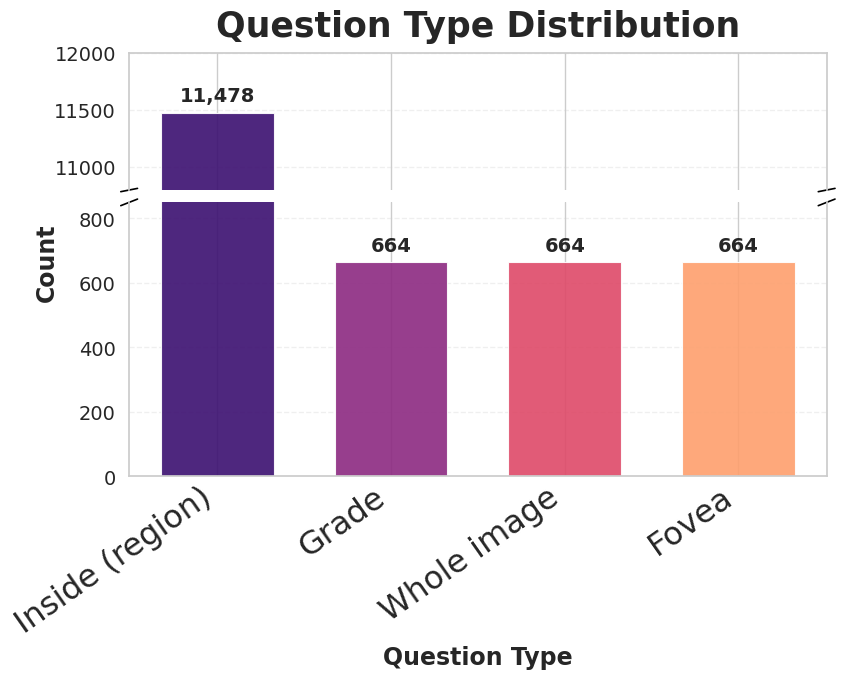

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Fixed order to make the figure reproducible
type_counts = df['question_type'].value_counts()
type_counts = type_counts.reindex(
    ['inside', 'grade', 'whole', 'fovea'],
    fill_value=0
)

positions = np.arange(len(type_counts))
colors = sns.color_palette('magma', n_colors=len(type_counts))

# Names displayed on the X-axis
labels = {
    'inside': 'Inside (region)',
    'grade': 'Grade',
    'whole': 'Whole image',
    'fovea': 'Fovea'
}

fig, (ax_upper, ax_lower) = plt.subplots(
    2, 1,
    sharex=True,
    figsize=(9, 5.5),
    gridspec_kw={'height_ratios': [1, 2], 'hspace': 0.06}
)

for ax in (ax_upper, ax_lower):
    ax.bar(
        positions,
        type_counts.values,
        width=0.65,
        color=colors,
        edgecolor='white',
        linewidth=0.8,
        alpha=0.9
    )
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)
    ax.tick_params(axis='y', labelsize=14)

# Limits of the broken Y-axis
ax_lower.set_ylim(0, 850)
ax_upper.set_ylim(10800, 12000)

# Hide the borders where the break occurs
ax_upper.spines['bottom'].set_visible(False)
ax_lower.spines['top'].set_visible(False)
ax_upper.tick_params(axis='x', bottom=False, labelbottom=False)
ax_lower.tick_params(axis='x', length=0)

# Diagonal marks indicating the axis break
break_mark = 0.012
style = dict(color='black', linewidth=1.2, clip_on=False)

for x in (0, 1):
    ax_upper.plot(
        (x - break_mark, x + break_mark), (-break_mark, +break_mark),
        transform=ax_upper.transAxes, **style
    )
    ax_lower.plot(
        (x - break_mark, x + break_mark), (1 - break_mark, 1 + break_mark),
        transform=ax_lower.transAxes, **style
    )

# Frequency above each bar
for x, value in zip(positions, type_counts.values):
    ax = ax_upper if value > ax_lower.get_ylim()[1] else ax_lower
    ax.annotate(
        f'{value:,}',
        (x, value),
        xytext=(0, 5),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=14,
        fontweight='bold'
    )

ax_lower.set_xticks(positions)
ax_lower.set_xticklabels(
    [labels[question_type] for question_type in type_counts.index],
    rotation=35,
    ha='right',
    fontsize=23
)

ax_upper.set_title(
    'Question Type Distribution',
    fontsize=25,
    fontweight='bold',
    pad=12
)
ax_lower.set_xlabel('Question Type', fontsize=17, fontweight='bold')
fig.supylabel('Count', fontsize=17, fontweight='bold')

plt.show()

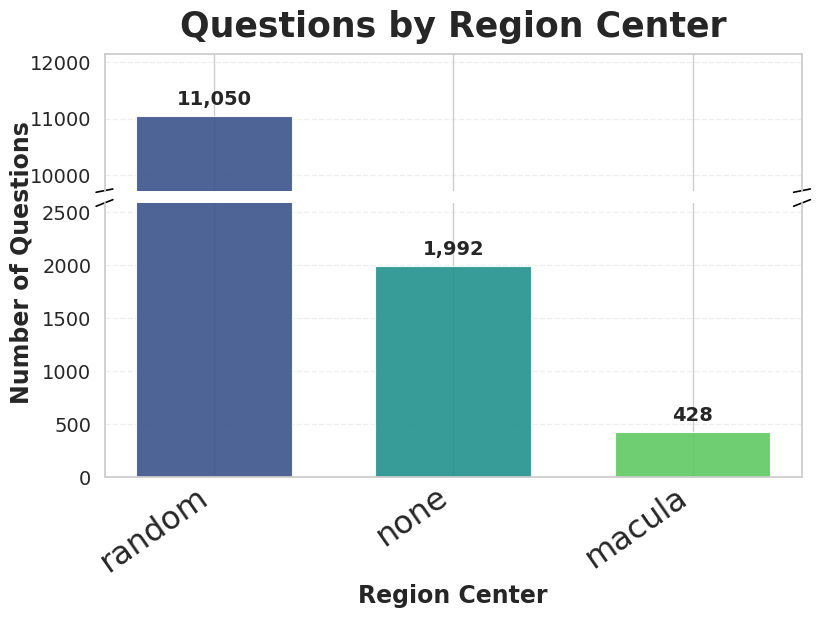

In [7]:
# ============================================================
# FIGURE 2: QUESTIONS BY CENTER, WITH A BROKEN Y-AXIS
# ============================================================

# Normalize questions before counting
questions = (
    df['question']
    .fillna('')
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r'\s+', ' ', regex=True)
    .str.replace(r'\s+([?.!,;:])', r'\1', regex=True)
)

questions = questions[questions != '']

top_questions = questions.value_counts().head(10)

question_labels = [
    question if len(question) <= 70
    else question[:67] + '...'
    for question in top_questions.index
]

# Define center_counts
center_counts = df['center'].value_counts()

positions = np.arange(len(center_counts))
values = center_counts.values

if len(values) < 2:
    raise ValueError("At least two categories are required to define the break.")

highest = values.max()
second_highest = np.sort(values)[-2]

if highest < second_highest * 2:
    raise ValueError(
        "The frequencies are too close; in this case "
        "it is preferable to use a continuous Y-axis."
    )

# The break is between the second-highest and highest bars
lower_limit = second_highest * 1.30
upper_limit = highest * 0.88

fig, (ax_upper, ax_lower) = plt.subplots(
    2, 1,
    sharex=True,
    figsize=(9, 5.5),
    gridspec_kw={'height_ratios': [1, 2], 'hspace': 0.06}
)

colors = sns.color_palette('viridis', n_colors=len(center_counts))

for ax in (ax_upper, ax_lower):
    ax.bar(
        positions,
        values,
        width=0.65,
        color=colors,
        edgecolor='white',
        linewidth=0.8,
        alpha=0.9
    )
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)
    ax.tick_params(axis='y', labelsize=14)

ax_lower.set_ylim(0, lower_limit)
ax_upper.set_ylim(upper_limit, highest * 1.10)

# Visually mark the break
ax_upper.spines['bottom'].set_visible(False)
ax_lower.spines['top'].set_visible(False)
ax_upper.tick_params(axis='x', bottom=False, labelbottom=False)
ax_lower.tick_params(axis='x', length=0)

break_mark = 0.012
style = dict(color='black', linewidth=1.2, clip_on=False)

for x in (0, 1):
    ax_upper.plot(
        (x - break_mark, x + break_mark), (-break_mark, +break_mark),
        transform=ax_upper.transAxes, **style
    )
    ax_lower.plot(
        (x - break_mark, x + break_mark), (1 - break_mark, 1 + break_mark),
        transform=ax_lower.transAxes, **style
    )

# Place each value above the visible portion of its bar
for x, value in zip(positions, values):
    ax = ax_upper if value > lower_limit else ax_lower
    ax.annotate(
        f'{value:,}',
        (x, value),
        xytext=(0, 5),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=14,
        fontweight='bold'
    )

ax_lower.set_xticks(positions)
ax_lower.set_xticklabels(
    center_counts.index,
    rotation=35,
    ha='right',
    fontsize=23
)

ax_upper.set_title(
    'Questions by Region Center',
    fontsize=25,
    fontweight='bold',
    pad=12
)
ax_lower.set_xlabel(
    'Region Center',
    fontsize=17,
    fontweight='bold'
)
fig.supylabel(
    'Number of Questions',
    fontsize=17,
    fontweight='bold'
)

plt.show()

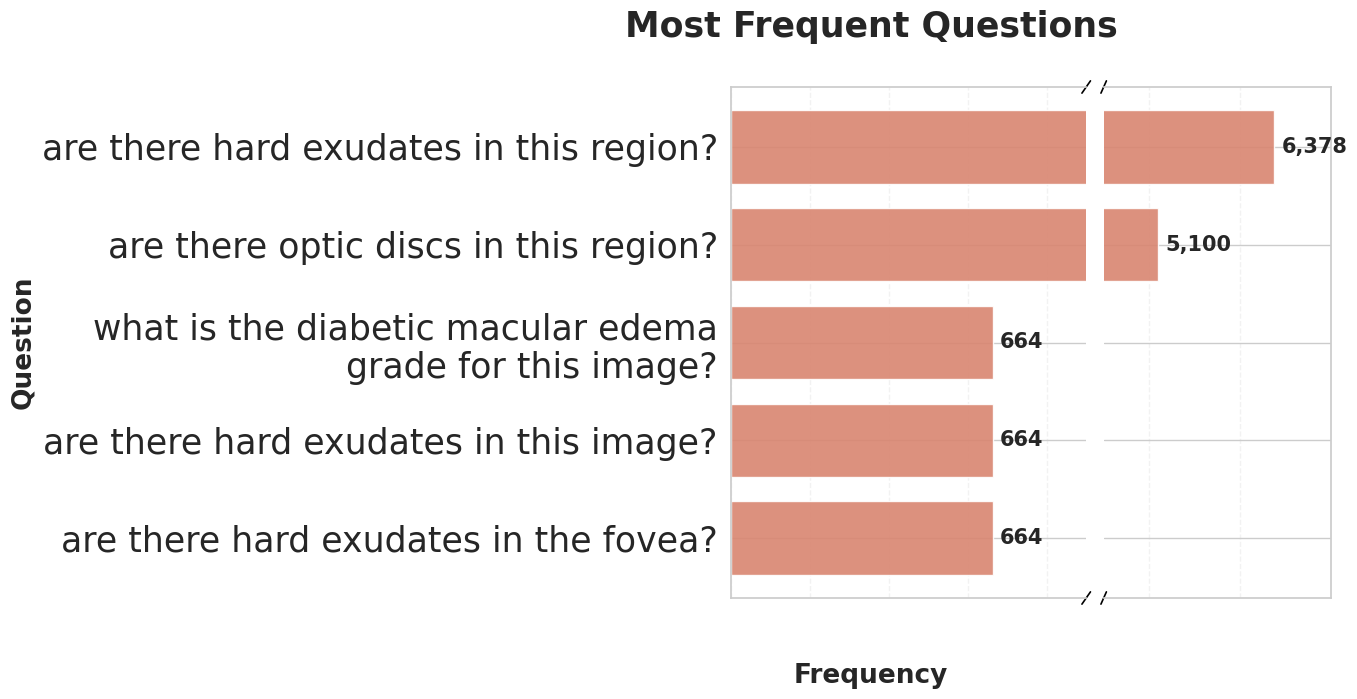

In [8]:
# ============================================================
# FIGURE 3: MOST FREQUENT QUESTIONS - BROKEN X-AXIS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Normalize questions before counting them
questions = (
    df['question']
    .fillna('')
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r'\s+', ' ', regex=True)
    .str.replace(r'\s+([?.!,;:])', r'\1', regex=True)
)

questions = questions[questions != '']
top_questions = questions.value_counts().head(10)

if top_questions.empty:
    raise ValueError("There are no valid questions to plot.")

labels = [
    question if len(question) <= 70
    else question[:67] + '...'
    for question in top_questions.index
]

labels = [
    label.replace(
        'what is the diabetic macular edema grade for this image?',
        'what is the diabetic macular edema\ngrade for this image?'
    )
    for label in labels
]

values = top_questions.values
positions = np.arange(len(top_questions)) * 0.60

# These limits correspond to the displayed distribution:
# 664 | break | 5,100 and 6,378
left_limit = 900
right_limit = 4500

fig, (ax_left, ax_right) = plt.subplots(
    1, 2,
    sharey=True,
    figsize=(10, 7),
    gridspec_kw={
        'width_ratios': [2.5, 1.6],
        'wspace': 0.06
    }
)

for ax in (ax_left, ax_right):
    ax.barh(
        positions,
        values,
        height=0.45,
        color='#D98570',
        alpha=0.9
    )
    ax.grid(axis='x', linestyle='--', alpha=0.25)
    ax.set_axisbelow(True)
    ax.tick_params(axis='x', labelbottom=False)

ax_left.set_xlim(0, left_limit)
ax_right.set_xlim(right_limit, 7000)

# Question labels
ax_left.set_yticks(positions)
ax_left.set_yticklabels(labels, fontsize=25)
ax_left.invert_yaxis()
ax_right.tick_params(axis='y', left=False, labelleft=False)

# Hide the borders that meet at the break
ax_left.spines['right'].set_visible(False)
ax_right.spines['left'].set_visible(False)

# Diagonal marks for the broken axis
break_mark = 0.012
style = dict(color='black', linewidth=1.2, clip_on=False)

for y in (0, 1):
    ax_left.plot(
        (1 - break_mark, 1 + break_mark),
        (y - break_mark, y + break_mark),
        transform=ax_left.transAxes,
        **style
    )
    ax_right.plot(
        (-break_mark, +break_mark),
        (y - break_mark, y + break_mark),
        transform=ax_right.transAxes,
        **style
    )

# Frequency at the end of each bar
for position, value in zip(positions, values):
    ax = ax_right if value > left_limit else ax_left
    ax.annotate(
        f'{value:,}',
        (value, position),
        xytext=(5, 0),
        textcoords='offset points',
        ha='left',
        va='center',
        fontsize=15,
        fontweight='bold'
    )

fig.suptitle(
    'Most Frequent Questions',
    fontsize=25,
    fontweight='bold',
    y=0.98
)
ax_left.set_ylabel('Question', fontsize=19, fontweight='bold')
fig.supxlabel('Frequency', fontsize=19, fontweight='bold')

fig.subplots_adjust(
    left=0.36,
    right=0.96,
    top=0.87,
    bottom=0.14
)

plt.show()

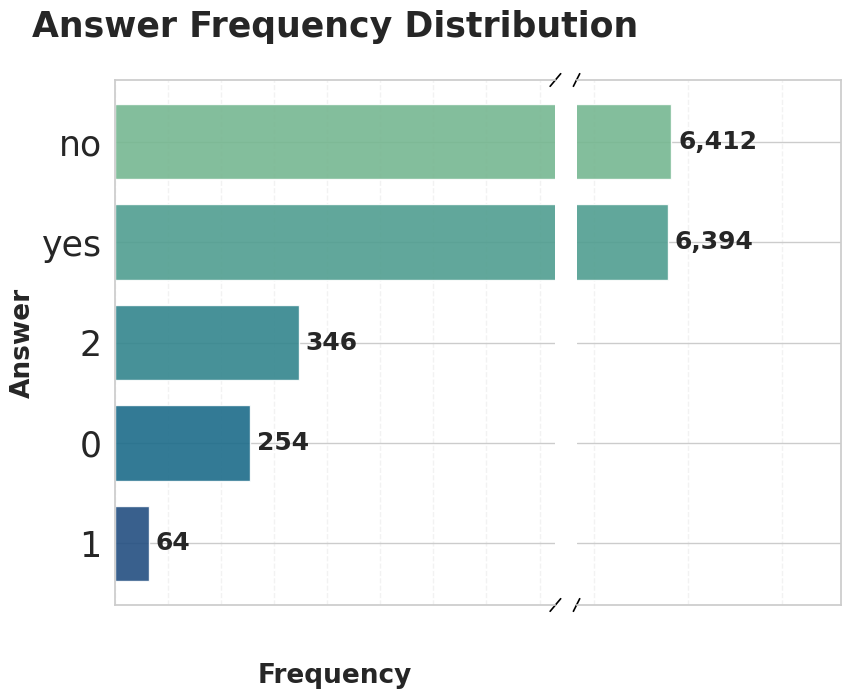

In [9]:
# ============================================================
# FIGURE 4: FREQUENCY OF ANSWER CATEGORIES
# BROKEN X-AXIS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Normalize answers
answers = (
    df['answer']
    .fillna('')
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r'\s+', ' ', regex=True)
)

answers = answers[answers != '']
answer_counts = answers.value_counts()

if answer_counts.empty:
    raise ValueError("There are no valid answers to plot.")

# Find the largest gap between distinct frequencies
frequencies = np.sort(answer_counts.unique())
gaps = np.diff(frequencies)

if len(gaps) == 0 or gaps.max() == 0:
    raise ValueError(
        "All categories have the same frequency; "
        "there is no suitable interval for breaking the axis."
    )

break_index = np.argmax(gaps)
lower_frequency = frequencies[break_index]
upper_frequency = frequencies[break_index + 1]

# Leave a small margin around the bars
margin = (upper_frequency - lower_frequency) * 0.08
left_limit = lower_frequency + margin
right_limit = upper_frequency - margin

positions = np.arange(len(answer_counts)) * 0.60
values = answer_counts.values

colors = sns.color_palette(
    'crest',
    n_colors=len(answer_counts)
)

fig, (ax_left, ax_right) = plt.subplots(
    1, 2,
    sharey=True,
    figsize=(11, 7),
    gridspec_kw={
        'width_ratios': [2.5, 1.5],
        'wspace': 0.06
    }
)

for ax in (ax_left, ax_right):
    ax.barh(
        positions,
        values,
        color=colors,
        height=0.45,
        alpha=0.9
    )
    ax.grid(axis='x', linestyle='--', alpha=0.25)
    ax.set_axisbelow(True)
    ax.tick_params(axis='x', labelbottom=False)

ax_left.set_xlim(0, left_limit)
ax_right.set_xlim(
    right_limit,
    values.max() * 1.14
)

# Answer labels
ax_left.set_yticks(positions)
ax_left.set_yticklabels(
    answer_counts.index,
    fontsize=25
)
ax_left.invert_yaxis()

ax_right.tick_params(
    axis='y',
    left=False,
    labelleft=False
)

# Hide borders at the break point
ax_left.spines['right'].set_visible(False)
ax_right.spines['left'].set_visible(False)

# Diagonal marks indicating the broken axis
break_mark = 0.012
style = dict(
    color='black',
    linewidth=1.2,
    clip_on=False
)

for y in (0, 1):
    ax_left.plot(
        (1 - break_mark, 1 + break_mark),
        (y - break_mark, y + break_mark),
        transform=ax_left.transAxes,
        **style
    )
    ax_right.plot(
        (-break_mark, +break_mark),
        (y - break_mark, y + break_mark),
        transform=ax_right.transAxes,
        **style
    )

# Show the frequency at the visible end of each bar
for position, value in zip(positions, values):
    ax = ax_right if value > left_limit else ax_left
    ax.annotate(
        f'{value:,}',
        (value, position),
        xytext=(5, 0),
        textcoords='offset points',
        ha='left',
        va='center',
        fontsize=18,
        fontweight='bold'
    )

fig.suptitle(
    'Answer Frequency Distribution',
    fontsize=25,
    fontweight='bold',
    y=0.98
)
ax_left.set_ylabel(
    'Answer',
    fontsize=19,
    fontweight='bold'
)
fig.supxlabel(
    'Frequency',
    fontsize=19,
    fontweight='bold'
)

fig.subplots_adjust(
    left=0.30,
    right=0.96,
    top=0.88,
    bottom=0.13
)

plt.show()

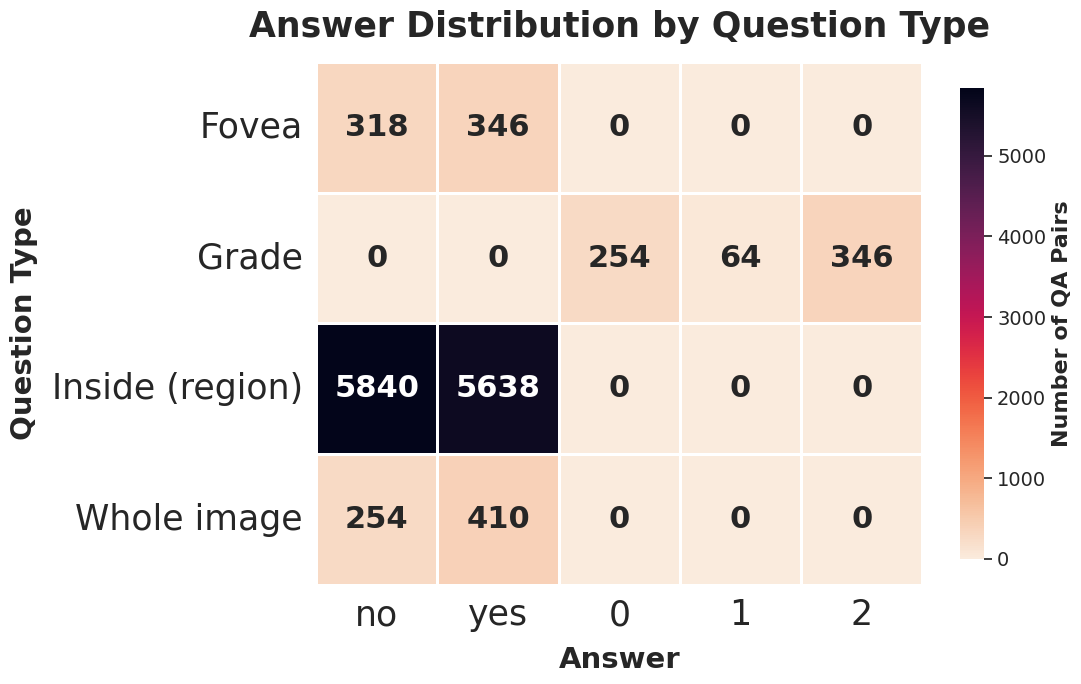

In [10]:
# ============================================================
# FIGURE 5: ANSWER DISTRIBUTION BY QUESTION TYPE
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create a copy with the required columns
df_heatmap = df[['question_type', 'answer']].copy()

# Normalize question types
df_heatmap['question_type'] = (
    df_heatmap['question_type']
    .fillna('')
    .astype(str)
    .str.strip()
    .str.lower()
)

# Normalize answers
df_heatmap['answer'] = (
    df_heatmap['answer']
    .fillna('')
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r'\s+', ' ', regex=True)
)

# Remove empty or unknown records
df_heatmap = df_heatmap[
    ~df_heatmap['question_type'].isin(
        ['', 'unknown', 'nan', 'none']
    )
    & (df_heatmap['answer'] != '')
]

# Create a frequency table
heatmap_table = pd.crosstab(
    df_heatmap['question_type'],
    df_heatmap['answer']
)

# Row and column order
type_order = ['fovea', 'grade', 'inside', 'whole']
answer_order = ['no', 'yes', '0', '1', '2']

# Verify that the order does not omit values present in the dataset
excluded_types = set(heatmap_table.index) - set(type_order)
excluded_answers = set(heatmap_table.columns) - set(answer_order)

if excluded_types or excluded_answers:
    raise ValueError(
        f"Values are omitted from the figure. "
        f"Types: {sorted(excluded_types)}; "
        f"Answers: {sorted(excluded_answers)}"
    )

heatmap_table = heatmap_table.reindex(
    index=type_order,
    columns=answer_order,
    fill_value=0
)

# Readable labels consistent with the table in the article
type_labels = [
    'Fovea',
    'Grade',
    'Inside (region)',
    'Whole image'
]

fig, ax = plt.subplots(figsize=(11, 7))

sns.heatmap(
    heatmap_table,
    annot=True,
    fmt='d',
    cmap='rocket_r',
    linewidths=0.8,
    linecolor='white',
    cbar_kws={
        'label': 'Number of QA Pairs',
        'shrink': 0.90
    },
    annot_kws={
        'fontsize': 22,
        'fontweight': 'bold'
    },
    ax=ax
)

ax.set_title(
    'Answer Distribution by Question Type',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Answer',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_ylabel(
    'Question Type',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_xticklabels(
    answer_order,
    rotation=0,
    fontsize=25
)

ax.set_yticklabels(
    type_labels,
    rotation=0,
    fontsize=25
)

# Color bar formatting
colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=14)
colorbar.set_label(
    'Number of QA Pairs',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

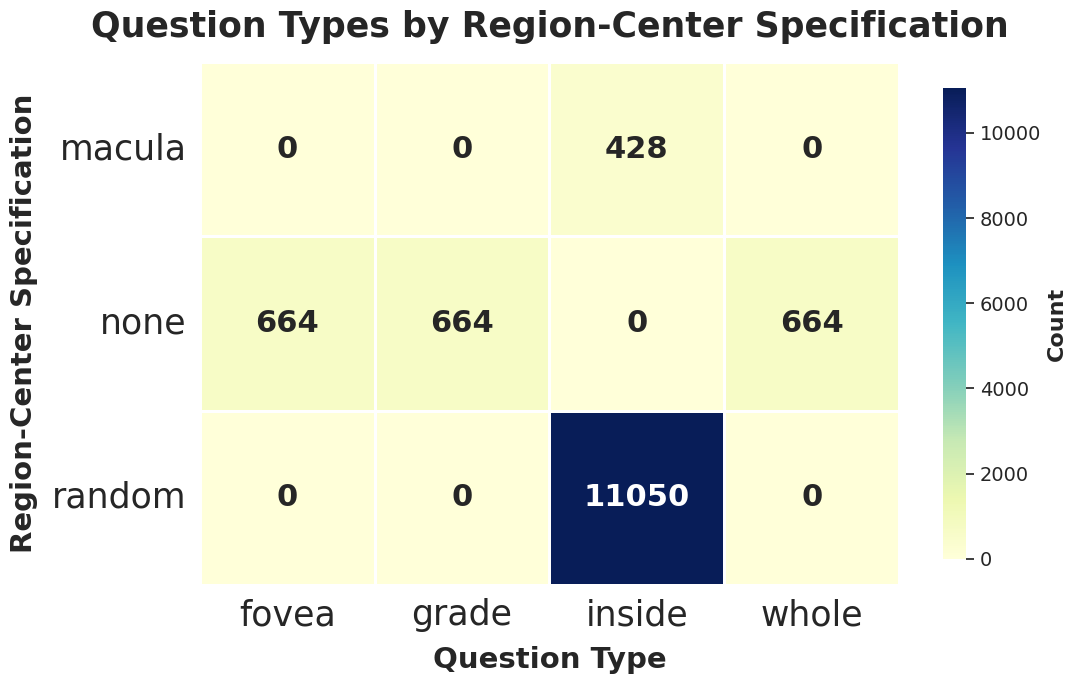

In [11]:
# ============================================================
# FIGURE 6: QUESTION TYPE DISTRIBUTION BY CENTER
# ============================================================

# Create a copy with the required columns
df_center_type = df[
    ['center', 'question_type']
].copy()

# Normalize the centers
df_center_type['center'] = (
    df_center_type['center']
    .fillna('unknown')
    .astype(str)
    .str.strip()
    .str.lower()
)

# Normalize question types
df_center_type['question_type'] = (
    df_center_type['question_type']
    .fillna('unknown')
    .astype(str)
    .str.strip()
    .str.lower()
)

# Remove empty or unknown values
df_center_type = df_center_type[
    ~df_center_type['center'].isin([
        '',
        'unknown',
        'nan'
    ])
    &
    ~df_center_type['question_type'].isin([
        '',
        'unknown',
        'nan',
        'none'
    ])
]

# Create a frequency table
center_type_table = pd.crosstab(
    df_center_type['center'],
    df_center_type['question_type']
)

# Order shown in the figure
center_order = [
    'macula',
    'none',
    'random'
]

type_order = [
    'fovea',
    'grade',
    'inside',
    'whole'
]

# Apply the order and fill missing combinations
center_type_table = center_type_table.reindex(
    index=center_order,
    columns=type_order,
    fill_value=0
)

# Create the figure
fig, ax = plt.subplots(figsize=(11, 7))

sns.heatmap(
    center_type_table,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    linewidths=0.8,
    linecolor='white',
    cbar_kws={
        'label': 'Number of QA Pairs',
        'shrink': 0.90
    },
    annot_kws={
        'fontsize': 22,
        'fontweight': 'bold'
    },
    ax=ax
)

ax.set_title(
    'Question Types by Region-Center Specification',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Question Type',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_ylabel(
    'Region-Center Specification',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_xticklabels(
    type_order,
    rotation=0,
    fontsize=25
)

ax.set_yticklabels(
    center_order,
    rotation=0,
    fontsize=25
)

# Configure the color bar
colorbar = ax.collections[0].colorbar

colorbar.ax.tick_params(
    labelsize=14
)

colorbar.set_label(
    'Count',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()